# CKA between monkeys N and F (same area)

Val split, batches of 64, CKA_S (Song), pooled over batches, as in the model evaluation (`Round3/monkey_cka/monkey_cka.py`).
Two batchings:
- **N_day**: the model evaluation's batches (one N day per batch; F's images can come from two days)
- **pair**: one (N day, F day) pair per batch

Window = mean over the area's bins of the pooled CKA_S: V1 bins 2-19, V4 5-19, IT 7-19 (as in training).

Input: `Round3/outputs/monkey_cka/monkey_cka.npz` (copied from Torch).

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

warnings.filterwarnings("ignore", category=RuntimeWarning)

CN = Path("~/Desktop/DynVision/CordsNet").expanduser()
d = np.load(CN / "Round3/outputs/monkey_cka/monkey_cka.npz")
areas = [str(a) for a in d["areas"]]
window = {a: d[f"window_bins_{a}"] for a in areas}
batchings = ["N_day", "pair"]
S = 1                                                   # CKA_S in the estimator axis
t_ms = d["bin_start_ms"] + 5                            # bin centers
color = {"N_day": "#2a78d6", "pair": "#eb6834"}
for b in batchings:
    print(f"{b}: {len(d[b + '_cka_batch'])} batches")

N_day: 27 batches
pair: 25 batches


### How the CKA numbers are computed

For one batch $b$ (64 images), one area and one 10 ms bin, with $X$ = monkey N responses (images × electrodes) and $Y$ = monkey F responses:

- Gram matrices $K = XX^\top$, $L = YY^\top$ (64 × 64, centered): how similar every pair of images is, for each monkey.
- Numerator $h_b(X,Y) = \mathrm{HSIC}(K, L)$: how much the two image-similarity structures agree.
- Denominators $h_b(X,X)$, $h_b(Y,Y)$: the strength of each monkey's own structure (normalization).
- CKA_S uses Song's unbiased HSIC: only pairs of *different* images, so the value does not depend on batch size.

**Per batch** (training's `cka_mean`): divide first, then average over the $B$ batches

$$\text{CKA}_{\text{per batch}} = \frac{1}{B}\sum_b \frac{h_b(X,Y)}{\sqrt{h_b(X,X)\,h_b(Y,Y)}}$$

**Pooled** (main number, evaluation's `cka_pooled`): average numerators and denominators first, then one ratio

$$\text{CKA}_{\text{pooled}} = \frac{\frac{1}{B}\sum_b h_b(X,Y)}{\sqrt{\frac{1}{B}\sum_b h_b(X,X)\;\cdot\;\frac{1}{B}\sum_b h_b(Y,Y)}}$$

Why pooled: each batch's terms are unbiased but noisy estimates. Averaging them first gives better estimates of the true numerator and denominators; a small noisy denominator in one batch would otherwise blow up that batch's ratio. Pooled is a weighted mean of the per-batch CKAs (batches with stronger structure count more).

Note: pooled is **not** CKA over all images at once. Only image pairs *within* a batch (one recording day) are compared; images from different batches are never paired.

**Window value**: mean of the pooled CKA over the area's bins (V1 2–19, V4 5–19, IT 7–19).

## 1. Table

Pooled = the main number (one ratio over all batches). Per batch = window CKA_S of each batch, mean and SD over batches.

In [2]:
rows = []
for j, a in enumerate(areas):
    r = {"area": a}
    for b in batchings:
        per_batch = np.nanmean(d[b + "_cka_batch"][:, j, window[a], S], axis=1)
        r[f"{b} pooled"] = d[b + "_window_pooled"][j, S]
        r[f"{b} per batch mean"] = per_batch.mean()
        r[f"{b} per batch SD"] = per_batch.std()
    r["pair - N_day (pooled)"] = r["pair pooled"] - r["N_day pooled"]
    rows.append(r)
table = pd.DataFrame(rows).set_index("area")
table.round(3)

,N_day pooled,N_day per batch mean,N_day per batch SD,pair pooled,pair per batch mean,pair per batch SD,pair - N_day (pooled)
area,,,,,,,
V1,0.428,0.424,0.048,0.449,0.440,0.073,0.020
V4,0.184,0.185,0.030,0.192,0.190,0.045,0.008
IT,0.118,0.121,0.032,0.127,0.126,0.036,0.008


- Minimal difference between the two ways of computing CKA **and** between the two ways of spliting a batch (restrict to one day or across days)
- For all three brain regions, pair CKAs (restrict to one day) are higher than N_day CKAs


## 2. Window CKA_S

Bars: pooled. Dots: individual batches.

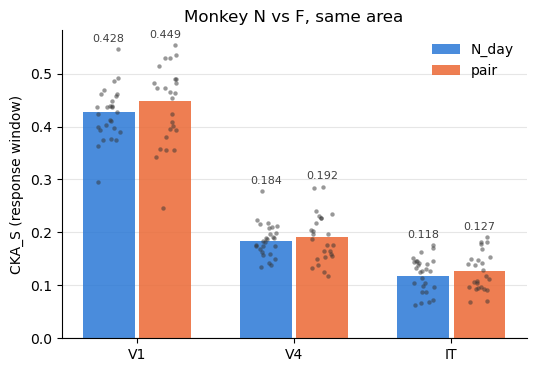

In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
x = np.arange(len(areas))
w = 0.36
rng = np.random.default_rng(0)
for i, b in enumerate(batchings):
    pos = x + (i - 0.5) * w
    vals = d[b + "_window_pooled"][:, S]
    ax.bar(pos, vals, w - 0.03, color=color[b], alpha=0.85, label=b)
    for j, a in enumerate(areas):
        per_batch = np.nanmean(d[b + "_cka_batch"][:, j, window[a], S], axis=1)
        ax.text(pos[j], max(vals[j], per_batch.max()) + 0.01, f"{vals[j]:.3f}", ha="center", va="bottom", fontsize=8, color="0.25")
        ax.scatter(pos[j] + rng.uniform(-w / 5, w / 5, len(per_batch)), per_batch, s=10, color="0.2", alpha=0.5, lw=0, zorder=3)
        
ax.set(xticks=x, xticklabels=areas, ylabel="CKA_S (response window)", title="Monkey N vs F, same area")
ax.axhline(0, color="0.6", lw=0.8)
ax.grid(axis="y", color="0.9")
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.show()

**Takeaway**: pair is slightly higher than N_day in all three areas (+0.008 to +0.020), consistent with mixing recording days within a batch lowering the measured CKA (day-to-day changes in recording conditions or the animal's state that per-day z-scoring does not remove). Not established: one batching seed only, the differences are small relative to the batch-to-batch spread, and the two batchings also differ in which images are used. Main number: N_day (identical batches to the model evaluation).

## 3. Per 10 ms bin

Pooled CKA_S per bin. Gray: the area's window.

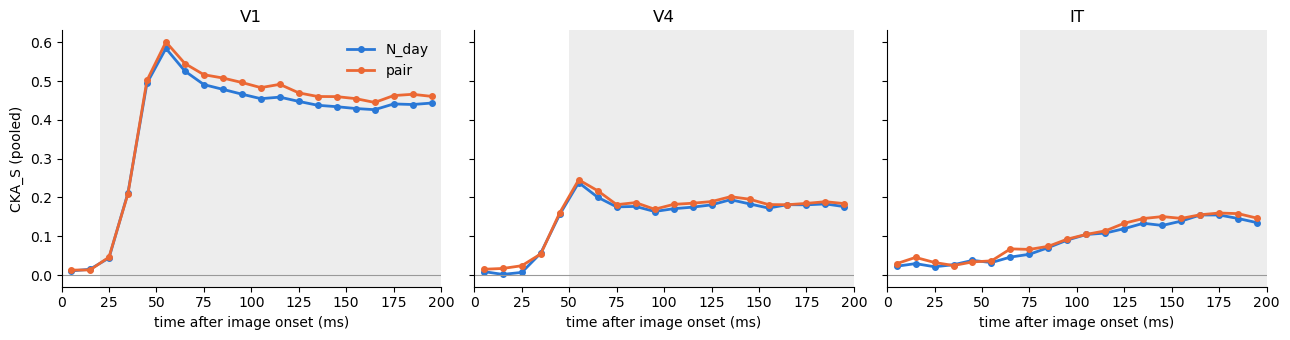

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
for j, (ax, a) in enumerate(zip(axes, areas)):
    ax.axvspan(window[a][0] * 10, 200, color="0.93", lw=0)
    for b in batchings:
        ax.plot(t_ms, d[b + "_cka_pooled"][j, :, S], color=color[b], lw=2, marker="o", ms=4, label=b)
    ax.axhline(0, color="0.6", lw=0.8)
    ax.set(title=a, xlabel="time after image onset (ms)", xlim=(0, 200))
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("CKA_S (pooled)")
axes[0].legend(frameon=False)
plt.tight_layout()
plt.show()